# EDA: DRS × plastic packaging recycling

## 0. Load the cleaned panel

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd

DATA_DIR = Path("data")   # outputs of build_drs_dataset_plastic_v2.ipynb

panel = pd.read_csv(
    DATA_DIR / "drs_recycling_panel_plastic.csv",
    dtype={"rate_flag": "string", "drs_group": "category", "deposit_structure": "category",
           "covers_metal": "boolean", "covers_glass": "boolean"},
)
panel["rate_flag"] = panel["rate_flag"].fillna("")
snap = pd.read_csv(DATA_DIR / "drs_deposit_snapshots_plastic.csv")
dictionary = pd.read_csv(DATA_DIR / "drs_recycling_panel_plastic_dictionary.csv")

assert not panel.duplicated(["geo", "year"]).any()
print("panel:", panel.shape, "| countries:", panel["geo"].nunique(),
      "| years:", panel["year"].min(), "-", panel["year"].max())
print("snapshots:", snap.shape)
panel.head()

panel: (720, 28) | countries: 30 | years: 2000 - 2023
snapshots: (24, 19)


,geo,country,year,plastic_recycling_rate,rate_flag,series_break_flag,post_2020_method_period,plastic_generated_kg_hab,plastic_recycled_kg_hab,share_recycled_abroad_pct,...,drs_note,deposit_max_eur,deposit_min_eur,deposit_plastic_min_eur,deposit_structure,deposit_source_year,deposit_is_snapshot_year,covers_metal,covers_glass,return_rate_pct
0,AT,Austria,2000,26.2,,False,0,NaN,NaN,NaN,...,Outside the data window,0.0,0.0,0.0,NaN,NaN,False,<NA>,<NA>,NaN
1,AT,Austria,2001,29.1,,False,0,NaN,NaN,NaN,...,Outside the data window,0.0,0.0,0.0,NaN,NaN,False,<NA>,<NA>,NaN
2,AT,Austria,2002,30.0,,False,0,NaN,NaN,NaN,...,Outside the data window,0.0,0.0,0.0,NaN,NaN,False,<NA>,<NA>,NaN
3,AT,Austria,2003,30.7,,False,0,NaN,NaN,NaN,...,Outside the data window,0.0,0.0,0.0,NaN,NaN,False,<NA>,<NA>,NaN
4,AT,Austria,2004,33.2,,False,0,NaN,NaN,NaN,...,Outside the data window,0.0,0.0,0.0,NaN,NaN,False,<NA>,<NA>,NaN


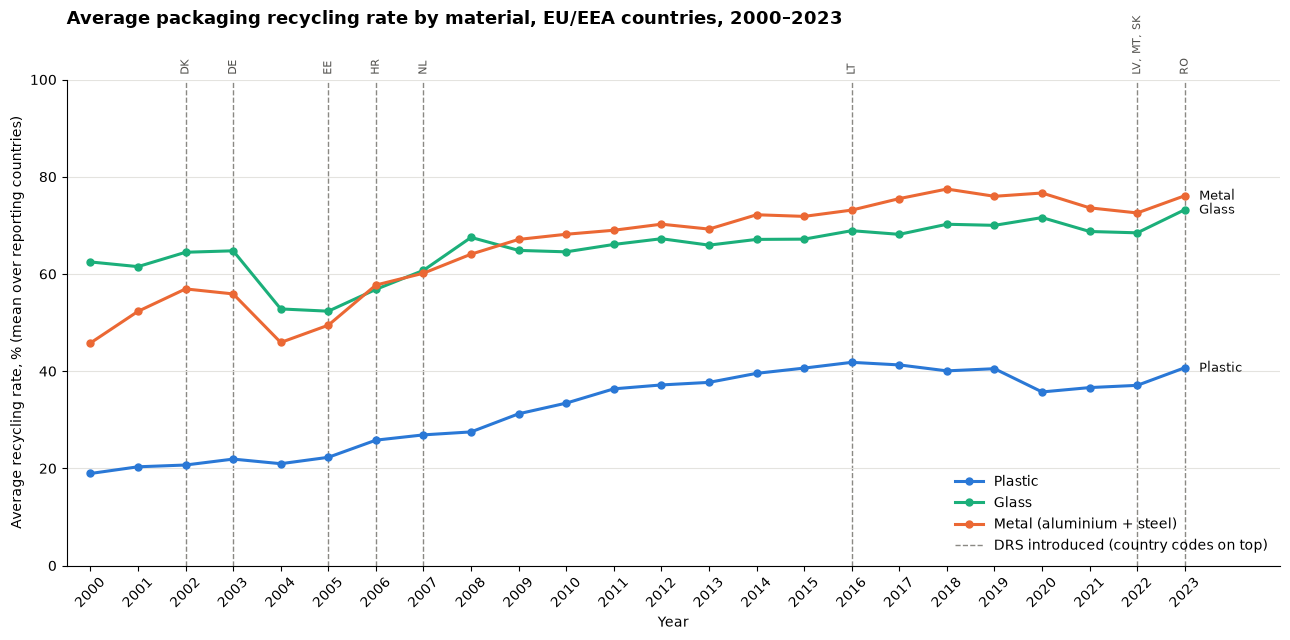

In [2]:
import json
import matplotlib.pyplot as plt


def read_rate(path):
    """Eurostat JSON-stat file with one waste type and one unit -> long table geo/year/rate."""
    with open(path, encoding="utf-8") as f:
        d = json.load(f)
    geo_idx, time_idx = (d["dimension"][k]["category"]["index"] for k in ("geo", "time"))
    n_time = len(time_idx)
    rows = [(g, int(t), d["value"].get(str(gi * n_time + ti)))
            for g, gi in geo_idx.items() for t, ti in time_idx.items()]
    return pd.DataFrame(rows, columns=["geo", "year", "rate"]).dropna()


MATERIALS = {   # label -> (file, colour)
    "Plastic": ("cei_wm020_plastic_page_jsonstat.json", "#2a78d6"),
    "Glass": ("cei_wm020_glass_page_jsonstat.json", "#1baf7a"),
    "Metal (aluminium + steel)": ("cei_wm020_metal_page_jsonstat.json", "#eb6834"),
}
countries = panel["geo"].unique()          # same 30 countries as the panel, no EU aggregates
means = pd.DataFrame({
    name: read_rate(DATA_DIR / file).query("geo in @countries").groupby("year")["rate"].mean()
    for name, (file, _) in MATERIALS.items()
})

# DRS introduction years inside the window (whole system, not plastic-specific)
starts = (panel.drop_duplicates("geo").dropna(subset=["drs_start_used"])
               .query("2000 < drs_start_used <= 2023")
               .groupby("drs_start_used")["geo"].apply(", ".join))

fig, ax = plt.subplots(figsize=(13, 6.5))
for yr, geos in starts.items():
    ax.axvline(yr, color="#8a8984", lw=1, ls="--", zorder=1)
    ax.text(yr, 1.01, geos, transform=ax.get_xaxis_transform(), rotation=90,
            ha="center", va="bottom", fontsize=8, color="#52514e")
for name, (_, colour) in MATERIALS.items():
    ax.plot(means.index, means[name], color=colour, lw=2.2, marker="o", markersize=5, label=name, zorder=3)
    ax.text(means.index[-1] + 0.3, means[name].iloc[-1], name.split(" ")[0], color="#0b0b0b",
            va="center", fontsize=9)

ax.plot([], [], color="#8a8984", lw=1, ls="--", label="DRS introduced (country codes on top)")
ax.set_xlim(means.index[0] - 0.5, means.index[-1] + 2)
ax.set_ylim(0, 100)
ax.set_xticks(means.index, means.index, rotation=45)
ax.set_xlabel("Year")
ax.set_ylabel("Average recycling rate, % (mean over reporting countries)")
ax.set_title("Average packaging recycling rate by material, EU/EEA countries, 2000–2023",
             fontsize=13, fontweight="bold", loc="left", pad=40)
ax.grid(axis="y", color="#e4e3df", lw=0.8)
ax.spines[["top", "right"]].set_visible(False)
ax.legend(frameon=False, loc="lower right")
plt.tight_layout()
plt.show()

## 2. Correlation: Pearson vs Spearman

$$r_{xy}=\frac{\sum_i (x_i-\bar x)(y_i-\bar y)}{\sqrt{\sum_i (x_i-\bar x)^2}\sqrt{\sum_i (y_i-\bar y)^2}} \qquad \rho_{xy}=r\big(\text{rank}(x),\ \text{rank}(y)\big)$$

Pairwise-complete country-years. Note: `deposit_max_eur` is 0 when there is no DRS, so its correlation with `has_drs` is mechanical.

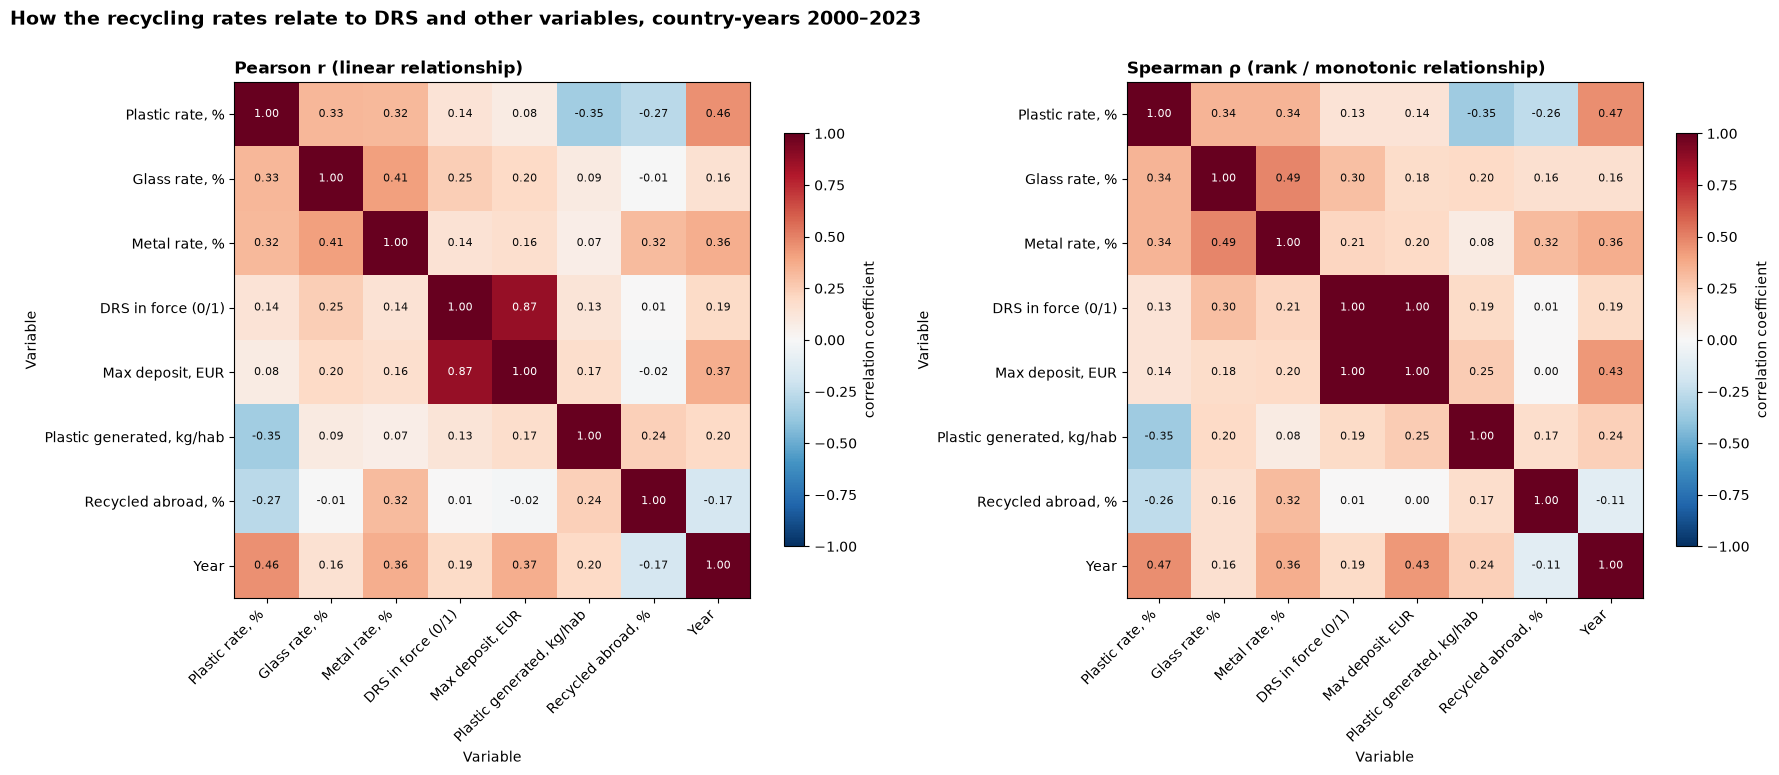

pairwise n per variable: {'Plastic rate, %': 630, 'Glass rate, %': 630, 'Metal rate, %': 630, 'DRS in force (0/1)': 720, 'Max deposit, EUR': 578, 'Plastic generated, kg/hab': 292, 'Recycled abroad, %': 164, 'Year': 720}


In [3]:
# Pearson vs Spearman correlation of the main variables (pairwise-complete country-years).
# Spearman works on ranks: robust to outliers (rates > 100%) and catches any monotonic, not only linear, link.
other = {name.split(" ")[0].lower(): read_rate(DATA_DIR / file).rename(columns={"rate": f"{name.split(' ')[0].lower()}_rate"})
         for name, (file, _) in MATERIALS.items() if not name.startswith("Plastic")}
df = panel.merge(other["glass"], on=["geo", "year"], how="left").merge(other["metal"], on=["geo", "year"], how="left")

VARS = {   # column -> short label
    "plastic_recycling_rate": "Plastic rate, %",
    "glass_rate": "Glass rate, %",
    "metal_rate": "Metal rate, %",
    "has_drs": "DRS in force (0/1)",
    "deposit_max_eur": "Max deposit, EUR",
    "plastic_generated_kg_hab": "Plastic generated, kg/hab",
    "share_recycled_abroad_pct": "Recycled abroad, %",
    "year": "Year",
}
X = df[list(VARS)].astype(float).rename(columns=VARS)
pearson, spearman = X.corr(method="pearson"), X.corr(method="spearman")

fig, axes = plt.subplots(1, 2, figsize=(18, 7.5))
for ax, m, title in [(axes[0], pearson, "Pearson r (linear relationship)"),
                     (axes[1], spearman, "Spearman ρ (rank / monotonic relationship)")]:
    im = ax.imshow(m.values, cmap="RdBu_r", vmin=-1, vmax=1)
    ax.set_xticks(range(len(m)), m.columns, rotation=45, ha="right")
    ax.set_yticks(range(len(m)), m.index)
    for i in range(len(m)):
        for j in range(len(m)):
            val = m.iat[i, j]
            ax.text(j, i, f"{val:.2f}", ha="center", va="center", fontsize=8,
                    color="white" if abs(val) > 0.6 else "#0b0b0b")
    ax.set_title(title, fontsize=12, fontweight="bold", loc="left")
    ax.set_xlabel("Variable")
    ax.set_ylabel("Variable")
    fig.colorbar(im, ax=ax, shrink=0.8, label="correlation coefficient")
fig.suptitle("How the recycling rates relate to DRS and other variables, country-years 2000–2023",
             fontsize=14, fontweight="bold", x=0.01, ha="left")
plt.tight_layout(rect=(0, 0, 1, 0.95))
plt.show()
print("pairwise n per variable:", X.notna().sum().to_dict())

## Heterogeneity of the DRS effect by scheme design

Two-way fixed effects (country $\alpha_i$, year $\gamma_t$), $D_{it}=\mathbb{1}[t \ge \text{start}_i]$:

- **A. By country** (adopters with years before and after): $\;y_{it}=\sum_c \beta_c\,\mathbb{1}[i=c]\,D_{it}+\beta_0 D^{\text{always}}_{it}+\alpha_i+\gamma_t+\varepsilon_{it}$, 95% CI $=\hat\beta_c \pm 1.96\,\text{SE}_{HC1}$
- **B. By feature category** $k$ (deposit structure / level / glass in scope): $\;y_{it}=\sum_k \beta_k\,D_{it}\,\mathbb{1}[i\in k]+\alpha_i+\gamma_t+\varepsilon_{it}$, SE clustered by country

OLS: $\hat\beta=(X'X)^{-1}X'y$; sandwich SE $\sqrt{\operatorname{diag}\big((X'X)^{-1}\,M\,(X'X)^{-1}\big)}$ with $M=\frac{n}{n-K}\sum_{it}\hat\varepsilon_{it}^2 x_{it}x_{it}'$ (HC1) or $M=\frac{G}{G-1}\frac{n-1}{n-K}\sum_g S_g S_g'$, $S_g=\sum_{it\in g}\hat\varepsilon_{it}x_{it}$ (cluster)

**Where:**
- $y_{it}$ — plastic packaging recycling rate of country $i$ in year $t$, %
- $D_{it}$ — DRS dummy: 1 if a plastic DRS is in force in country $i$ in year $t$, else 0; $\text{start}_i$ — year plastic entered the DRS
- $D^{\text{always}}_{it}$ — DRS dummy for countries with a DRS before 2000 (SE, IS, NO), kept separate so they do not mix with the adopters
- $\alpha_i$ — country fixed effect (permanent level of country $i$); $\gamma_t$ — year fixed effect (shock common to all countries in year $t$, incl. the 2020 method change)
- $\beta_c$ — DRS effect in country $c$, pp; $\beta_k$ — average DRS effect in scheme category $k$, pp; $\beta_0$ — effect for the always-treated countries (not plotted)
- $\mathbb{1}[\cdot]$ — indicator: 1 if the condition holds, else 0
- $\varepsilon_{it}$ — error term; $\hat\varepsilon_{it}$ — OLS residual
- $X$ — matrix of all regressors (DRS dummies + country and year dummies), $x_{it}$ — its row for country-year $it$; $n$ — number of country-years, $K$ — number of regressors
- $M$ — "meat" of the sandwich variance estimator; $G$ — number of clusters (countries), $S_g$ — sum of residual-weighted regressors in country $g$
- $\text{SE}_{HC1}$ — heteroskedasticity-robust standard error; 1.96 — 97.5% quantile of the normal distribution (95% CI)

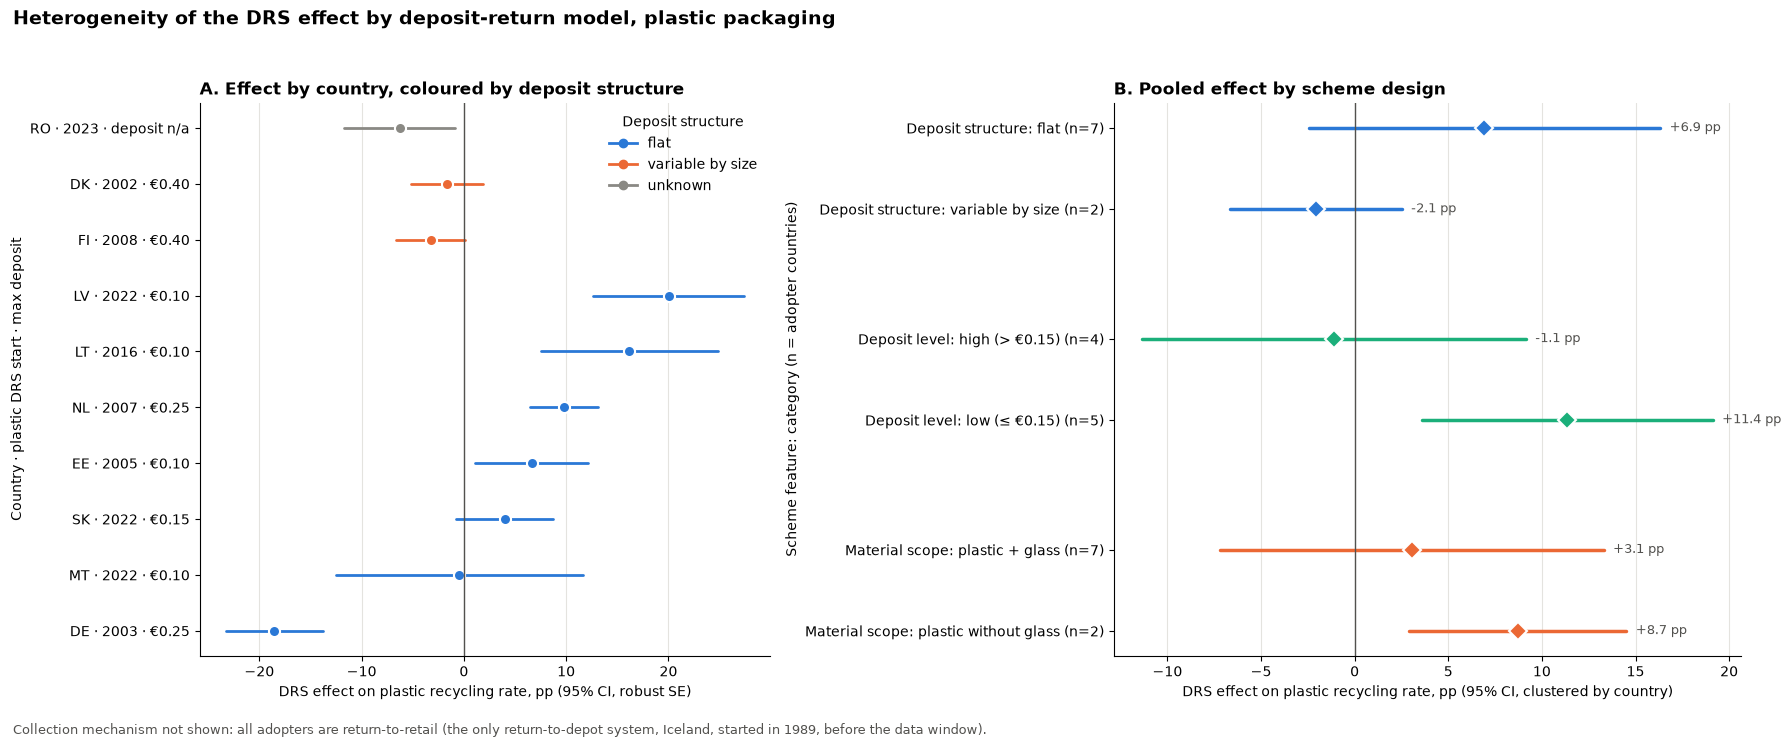

,effect,se,lo,hi,mechanism,Deposit structure,Deposit level,Material scope
DE,-18.52,2.44,-23.30,-13.74,Return-to-retail,flat,high (> €0.15),plastic + glass
MT,-0.46,6.17,-12.55,11.64,Return-to-retail,flat,low (≤ €0.15),plastic + glass
SK,4.00,2.42,-0.74,8.74,Return-to-retail,flat,low (≤ €0.15),plastic without glass
EE,6.62,2.80,1.13,12.10,Return-to-retail,flat,low (≤ €0.15),plastic + glass
NL,9.79,1.71,6.43,13.15,Return-to-retail,flat,high (> €0.15),plastic without glass
LT,16.19,4.41,7.55,24.82,Return-to-retail,flat,low (≤ €0.15),plastic + glass
LV,20.01,3.77,12.62,27.40,Return-to-retail,flat,low (≤ €0.15),plastic + glass
FI,-3.26,1.70,-6.59,0.07,Return-to-retail,variable by size,high (> €0.15),plastic + glass
DK,-1.66,1.79,-5.16,1.84,Return-to-retail,variable by size,high (> €0.15),plastic + glass
RO,-6.29,2.75,-11.68,-0.90,NaN,NaN,NaN,NaN


,feature,category,n,effect,lo,hi
0,Deposit structure,flat,7,6.93,-2.46,16.32
1,Deposit structure,variable by size,2,-2.07,-6.66,2.52
2,Deposit level,high (> €0.15),4,-1.10,-11.34,9.15
3,Deposit level,low (≤ €0.15),5,11.36,3.59,19.12
4,Material scope,plastic + glass,7,3.06,-7.19,13.30
5,Material scope,plastic without glass,2,8.71,2.90,14.51


In [4]:
# Heterogeneity of the DRS effect by the design of the deposit-return model.
# Effects come from the same two-way fixed-effects model as the hypothesis test
# (country + year effects), with the DRS dummy split by country or by scheme feature.
# Collection mechanism cannot be used: every country that introduced a DRS in 2000-2023 is
# return-to-retail; the only return-to-depot system (Iceland) dates from 1989, so it has no before/after.
latest = snap.dropna(subset=["deposit_max_eur"]).sort_values("snapshot_year").groupby("geo").last()
design = pd.DataFrame({
    "mechanism": snap.dropna(subset=["mechanism"]).groupby("geo")["mechanism"].last(),
    "Deposit structure": latest["deposit_structure"].str.split(" ").str[0].map({"flat": "flat", "variable": "variable by size"}),
    "Deposit level": np.where(latest["deposit_max_eur"] > 0.15, "high (> €0.15)", "low (≤ €0.15)"),
    "Material scope": np.where(latest["covers_glass"].astype(bool), "plastic + glass", "plastic without glass"),
})

h = panel.dropna(subset=["plastic_recycling_rate"])[["geo", "year", "plastic_recycling_rate", "plastic_drs_start"]].copy()
h["treat"] = (h["year"] >= h["plastic_drs_start"]).astype(float)
yh = h["plastic_recycling_rate"].to_numpy()
FEh = np.column_stack([np.ones(len(h)), pd.get_dummies(h[["geo", "year"]].astype(str), drop_first=True).to_numpy(float)])

# adopters with observed years both before and after the DRS start (HR has none before, so it drops out)
pp = h[h["plastic_drs_start"].between(2001, 2023)].groupby("geo")["treat"].agg(["min", "max"])
adopt = pp[(pp["min"] == 0) & (pp["max"] == 1)].index.tolist()
h = h.join(design, on="geo")


def ols_effects(D, cluster=None):
    """Coefficients and 95% CI for the columns of D in y ~ D + country FE + year FE.
    cluster=None -> heteroskedasticity-robust (HC1) SE; otherwise clustered by `cluster`."""
    Xf = np.column_stack([D, FEh])
    keep = np.flatnonzero(np.abs(Xf).sum(0) > 0)
    Xf = Xf[:, keep]
    XtX_inv = np.linalg.pinv(Xf.T @ Xf)
    b = XtX_inv @ Xf.T @ yh
    e = yh - Xf @ b
    n, k = Xf.shape
    if cluster is None:
        meat = (Xf * e[:, None]).T @ (Xf * e[:, None]) * n / (n - k)
    else:
        groups = pd.factorize(cluster)[0]
        S = np.vstack([np.bincount(groups, weights=Xf[:, j] * e) for j in range(k)]).T
        g = S.shape[0]
        meat = S.T @ S * g / (g - 1) * (n - 1) / (n - k)
    se = np.sqrt(np.diag(XtX_inv @ meat @ XtX_inv))
    return pd.DataFrame({"effect": b[:D.shape[1]], "se": se[:D.shape[1]]}).assign(
        lo=lambda x: x["effect"] - 1.96 * x["se"], hi=lambda x: x["effect"] + 1.96 * x["se"])


# A. one DRS effect per adopter country
Dc = np.column_stack([(h["geo"].eq(g) & h["treat"].eq(1)).to_numpy(float) for g in adopt])
other_treat = (h["treat"].eq(1) & ~h["geo"].isin(adopt)).to_numpy(float)   # always-treated countries
by_country = ols_effects(np.column_stack([Dc, other_treat]))[:len(adopt)]
by_country.index = adopt
by_country = by_country.join(design).sort_values(["Deposit structure", "effect"])

# B. one DRS effect per category of each scheme feature (SE clustered by country)
rows = []
for feature in ["Deposit structure", "Deposit level", "Material scope"]:
    cats = sorted(h.loc[h["geo"].isin(adopt), feature].dropna().unique())
    D = np.column_stack([(h["treat"].eq(1) & h[feature].eq(c)).to_numpy(float) for c in cats]
                        + [(h["treat"].eq(1) & ~h[feature].isin(cats)).to_numpy(float)])
    est = ols_effects(D, cluster=h["geo"].to_numpy())[:len(cats)]
    for c, r in zip(cats, est.itertuples()):
        n_c = h.loc[h["geo"].isin(adopt) & h[feature].eq(c), "geo"].nunique()
        rows.append(dict(feature=feature, category=c, n=n_c, effect=r.effect, lo=r.lo, hi=r.hi))
by_feature = pd.DataFrame(rows)

COLORS = {"flat": "#2a78d6", "variable by size": "#eb6834"}
fig, axes = plt.subplots(1, 2, figsize=(18, 7.5), gridspec_kw={"width_ratios": [1, 1.1]})

ax = axes[0]
ypos = np.arange(len(by_country))
for yv, (geo, r) in zip(ypos, by_country.iterrows()):
    c = COLORS.get(r["Deposit structure"], "#8a8984")
    ax.plot([r["lo"], r["hi"]], [yv, yv], color=c, lw=2, solid_capstyle="round")
    ax.plot(r["effect"], yv, "o", color=c, markersize=8, markeredgecolor="white", markeredgewidth=1.5)
ax.axvline(0, color="#52514e", lw=1)
ax.set_yticks(ypos, [f"{g} · {int(panel.loc[panel.geo == g, 'plastic_drs_start'].iat[0])} · "
                     + (f"€{latest.loc[g, 'deposit_max_eur']:.2f}" if g in latest.index else "deposit n/a") for g in by_country.index])
ax.set_xlabel("DRS effect on plastic recycling rate, pp (95% CI, robust SE)")
ax.set_ylabel("Country · plastic DRS start · max deposit")
ax.set_title("A. Effect by country, coloured by deposit structure", fontsize=12, fontweight="bold", loc="left")
ax.legend(handles=[plt.Line2D([], [], color=c, marker="o", lw=2, label=k)
                   for k, c in {**COLORS, "unknown": "#8a8984"}.items()],
          title="Deposit structure", frameon=False, loc="upper right")
ax.grid(axis="x", color="#e4e3df", lw=0.8)
ax.spines[["top", "right"]].set_visible(False)

ax = axes[1]
FEATURE_COLORS = {"Deposit structure": "#2a78d6", "Deposit level": "#1baf7a", "Material scope": "#eb6834"}
labels, ypos2, y0 = [], [], 0
for feature, grp in by_feature.groupby("feature", sort=False):
    for r in grp.itertuples():
        ax.plot([r.lo, r.hi], [y0, y0], color=FEATURE_COLORS[feature], lw=2.5, solid_capstyle="round")
        ax.plot(r.effect, y0, "D", color=FEATURE_COLORS[feature], markersize=9, markeredgecolor="white", markeredgewidth=1.5)
        ax.text(r.hi + 0.5, y0, f"{r.effect:+.1f} pp", va="center", fontsize=9, color="#52514e")
        labels.append(f"{feature}: {r.category} (n={r.n})")
        ypos2.append(y0)
        y0 += 1
    y0 += 0.6
ax.axvline(0, color="#52514e", lw=1)
ax.set_yticks(ypos2, labels)
ax.invert_yaxis()
ax.set_xlabel("DRS effect on plastic recycling rate, pp (95% CI, clustered by country)")
ax.set_ylabel("Scheme feature: category (n = adopter countries)")
ax.set_title("B. Pooled effect by scheme design", fontsize=12, fontweight="bold", loc="left")
ax.grid(axis="x", color="#e4e3df", lw=0.8)
ax.spines[["top", "right"]].set_visible(False)
fig.text(0.01, 0.01, "Collection mechanism not shown: all adopters are return-to-retail "
        "(the only return-to-depot system, Iceland, started in 1989, before the data window).",
        fontsize=9, color="#52514e", va="bottom")

fig.suptitle("Heterogeneity of the DRS effect by deposit-return model, plastic packaging",
             fontsize=14, fontweight="bold", x=0.01, ha="left")
plt.tight_layout(rect=(0, 0.04, 1, 0.95))
plt.show()
display(by_country.round(2))
display(by_feature.round(2))

## 3. Hypothesis test: does the DRS change the plastic recycling rate?

$$y_{it}=\beta D_{it}+\alpha_i+\gamma_t+\varepsilon_{it}, \qquad H_0:\beta=0 \quad \text{vs} \quad H_1:\beta\ne 0$$

- **A. Event study:** residual $e_{it}=y_{it}-\hat\alpha_i-\hat\gamma_t$, averaged by $k=t-\text{start}_i$: $\;\bar e_k \pm 1.96\,\frac{s_k}{\sqrt{n_k}}$. Under $H_0$ the line is flat around 0 after the dashed line.
- **B. Permutation test:** shuffle start years across countries $B=2000$ times, re-estimate $\hat\beta^{(b)}$; $\;p=\frac{1+\#\{|\hat\beta^{(b)}|\ge|\hat\beta|\}}{B+1}$

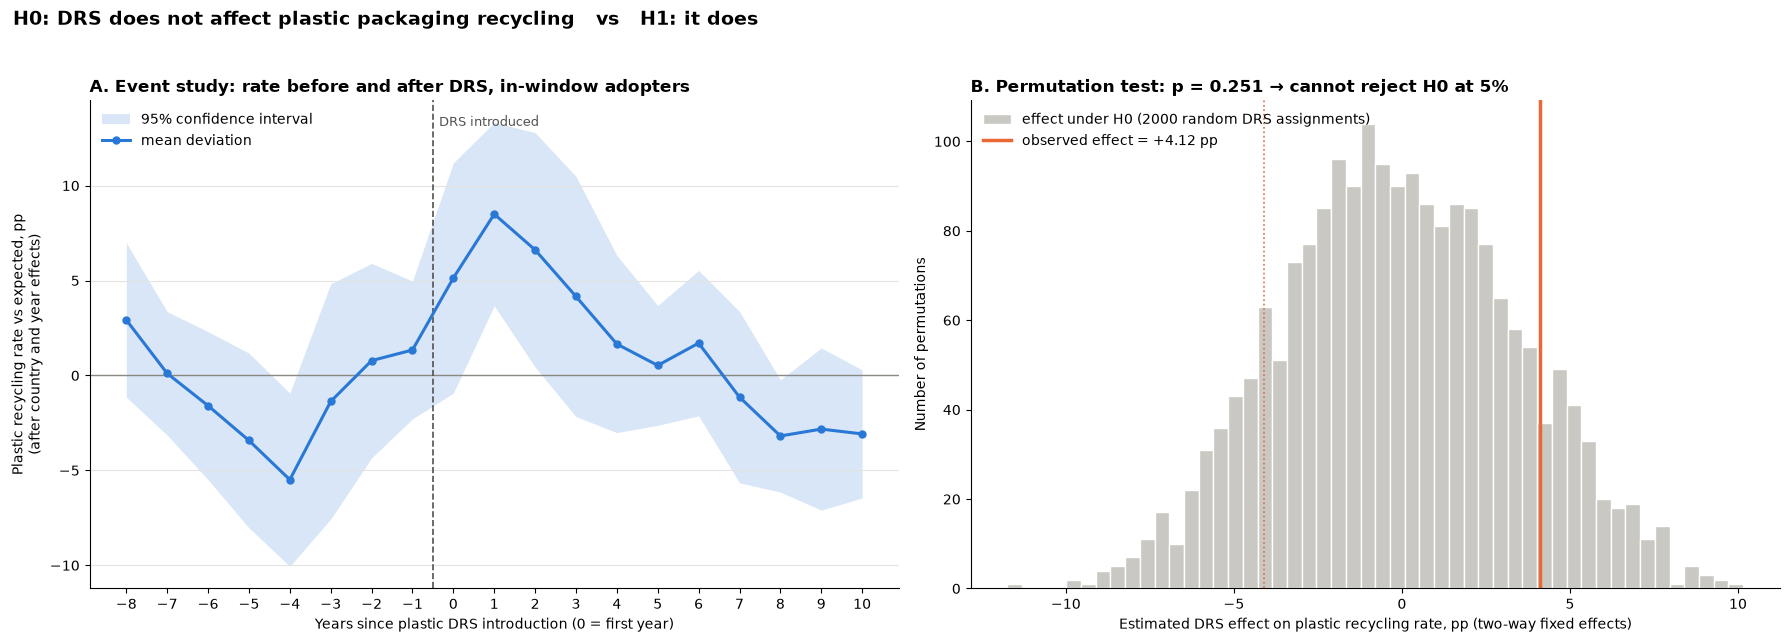

TWFE effect: +4.12 pp | permutation p-value: 0.251 | n = 630 country-years, 30 countries


k,-8.0,-7.0,-6.0,-5.0,-4.0,-3.0,-2.0,-1.0,0.0,1.0,2.0,3.0,4.0,5.0,6.0,7.0,8.0,9.0,10.0
mean,2.92,0.11,-1.59,-3.43,-5.49,-1.37,0.78,1.34,5.13,8.50,6.61,4.16,1.65,0.53,1.70,-1.14,-3.19,-2.83,-3.08
sem,2.07,1.66,1.99,2.35,2.33,3.16,2.61,1.85,3.09,2.46,3.15,3.23,2.38,1.61,1.95,2.30,1.51,2.18,1.72
count,6.00,7.00,7.00,7.00,7.00,8.00,9.00,10.00,10.00,9.00,6.00,6.00,6.00,6.00,7.00,7.00,6.00,6.00,6.00


In [5]:
# H0: DRS has no effect on the plastic recycling rate  vs  H1: it does.
# Estimator: two-way fixed effects, rate = b * has_drs + country effect + year effect + error.
# Country effects absorb fixed differences between countries; year effects absorb common shocks
# (incl. the 2020 reporting change). p-value by permutation: shuffle the DRS start years across
# countries many times and see how often a random assignment gives an effect at least as large.
d = panel.dropna(subset=["plastic_recycling_rate"])[["geo", "year", "plastic_recycling_rate", "plastic_drs_start"]]
y = d["plastic_recycling_rate"].to_numpy()
FE = pd.get_dummies(d[["geo", "year"]].astype(str), drop_first=True).to_numpy(float)
FE = np.column_stack([np.ones(len(d)), FE])
geo_codes, geo_idx = np.unique(d["geo"], return_inverse=True)
start_by_geo = d.groupby("geo")["plastic_drs_start"].first().reindex(geo_codes).to_numpy()


def twfe(starts):
    treat = (d["year"].to_numpy() >= starts[geo_idx]).astype(float)       # NaN start -> False
    beta, *_ = np.linalg.lstsq(np.column_stack([treat, FE]), y, rcond=None)
    return beta[0]


b_obs = twfe(start_by_geo)
rng = np.random.default_rng(42)
N_PERM = 2000
b_null = np.array([twfe(rng.permutation(start_by_geo)) for _ in range(N_PERM)])
p_value = (np.sum(np.abs(b_null) >= abs(b_obs)) + 1) / (N_PERM + 1)

# Event study: residual of the rate after removing country and year effects, by years since DRS
resid = y - FE @ np.linalg.lstsq(FE, y, rcond=None)[0]
ev = d.assign(resid=resid, k=d["year"] - d["plastic_drs_start"])
ev = ev[ev["plastic_drs_start"].between(2001, 2023) & ev["k"].between(-8, 10)]
es = ev.groupby("k")["resid"].agg(["mean", "sem", "count"])

fig, axes = plt.subplots(1, 2, figsize=(18, 6.5))

ax = axes[0]
ax.axhline(0, color="#8a8984", lw=1)
ax.axvline(-0.5, color="#52514e", lw=1.2, ls="--")
ax.fill_between(es.index, es["mean"] - 1.96 * es["sem"], es["mean"] + 1.96 * es["sem"],
                color="#2a78d6", alpha=0.18, lw=0, label="95% confidence interval")
ax.plot(es.index, es["mean"], color="#2a78d6", lw=2.2, marker="o", markersize=5, label="mean deviation")
ax.text(-0.35, 0.97, "DRS introduced", transform=ax.get_xaxis_transform(), fontsize=9, color="#52514e", va="top")
ax.set_xticks(es.index)
ax.set_xlabel("Years since plastic DRS introduction (0 = first year)")
ax.set_ylabel("Plastic recycling rate vs expected, pp\n(after country and year effects)")
ax.set_title("A. Event study: rate before and after DRS, in-window adopters", fontsize=12, fontweight="bold", loc="left")
ax.legend(frameon=False, loc="upper left")
ax.grid(axis="y", color="#e4e3df", lw=0.8)
ax.spines[["top", "right"]].set_visible(False)

ax = axes[1]
ax.hist(b_null, bins=50, color="#c9c8c2", edgecolor="white", label=f"effect under H0 ({N_PERM} random DRS assignments)")
ax.axvline(b_obs, color="#eb6834", lw=2.5, label=f"observed effect = {b_obs:+.2f} pp")
ax.axvline(-b_obs, color="#eb6834", lw=1.2, ls=":")
ax.set_xlabel("Estimated DRS effect on plastic recycling rate, pp (two-way fixed effects)")
ax.set_ylabel("Number of permutations")
verdict = "reject H0" if p_value < 0.05 else "cannot reject H0"
ax.set_title(f"B. Permutation test: p = {p_value:.3f} → {verdict} at 5%", fontsize=12, fontweight="bold", loc="left")
ax.legend(frameon=False, loc="upper left")
ax.spines[["top", "right"]].set_visible(False)

fig.suptitle("H0: DRS does not affect plastic packaging recycling   vs   H1: it does",
             fontsize=14, fontweight="bold", x=0.01, ha="left")
plt.tight_layout(rect=(0, 0, 1, 0.95))
plt.show()
print(f"TWFE effect: {b_obs:+.2f} pp | permutation p-value: {p_value:.3f} | n = {len(d)} country-years, "
      f"{d['geo'].nunique()} countries")
display(es.round(2).T)

## 4. Event study: DRS effect by year before and after introduction

$$y_{it}=\sum_{k\ne -1}\beta_k\,\mathbb{1}[t-\text{start}_i=k]+\alpha_i+\gamma_t+\varepsilon_{it}$$

Pre-trend test $H_0:\beta_k=0\ \forall k<-1$; effect test $H_0:\beta_k=0\ \forall k\ge 0$; Wald $W=\hat\beta_S'\,\hat V_S^{-1}\hat\beta_S\sim\chi^2_{|S|}$.

**Where:**
- $y_{it}$ — plastic recycling rate of country $i$ in year $t$, %; $\text{start}_i$ — year plastic entered the DRS
- $k$ — years relative to introduction ($k=0$ first DRS year); endpoints binned: $k\le-8$, $k\ge 8$; $k=-1$ is the reference (set to 0)
- $\beta_k$ — effect in event year $k$ relative to year $-1$, pp
- $\alpha_i$, $\gamma_t$ — country and year fixed effects; $\varepsilon_{it}$ — error
- $\hat\beta_S$, $\hat V_S$ — coefficients in set $S$ (pre or post years) and their covariance, SE clustered by country
- Sample: adopters 2001–2023 + countries with no DRS by 2023 (controls, all dummies 0); SE, IS, NO dropped (DRS before 2000)

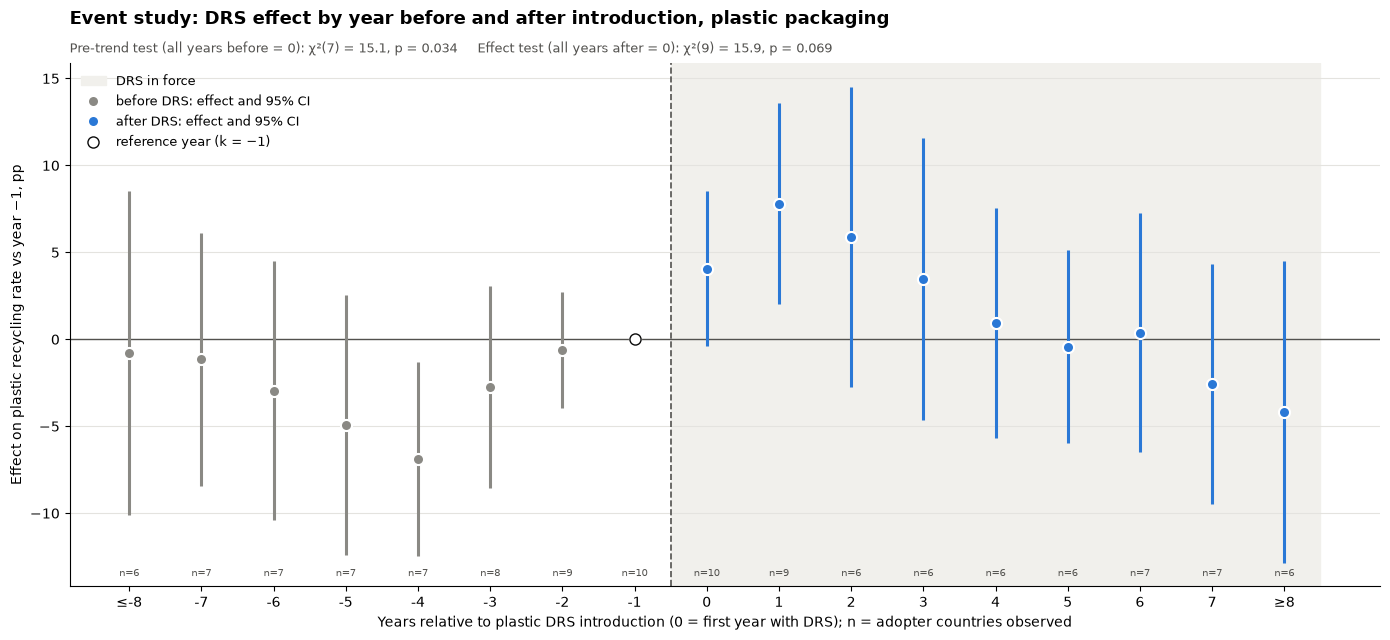

27 countries (11 adopters), 574 country-years; SE clustered by country


k,-8,-7,-6,-5,-4,-3,-2,-1,0,1,2,3,4,5,6,7,8
beta,-0.78,-1.16,-2.96,-4.91,-6.87,-2.75,-0.61,0.0,4.07,7.79,5.90,3.48,0.94,-0.44,0.38,-2.55,-4.17
lo,-10.10,-8.42,-10.40,-12.38,-12.47,-8.57,-3.92,0.0,-0.39,2.01,-2.73,-4.63,-5.69,-5.99,-6.51,-9.44,-12.85
hi,8.54,6.11,4.49,2.56,-1.28,3.07,2.71,0.0,8.53,13.57,14.53,11.58,7.58,5.11,7.27,4.34,4.51


In [6]:
# Event study: one DRS effect per year relative to introduction (k = -1 is the reference year).
# Sample: in-window adopters + countries with no DRS by 2023; countries with a DRS before 2000 are dropped
# (always treated, they have no "before"). Endpoints are binned: k <= -K_MAX and k >= K_MAX.
import math

K_MAX = 8
es_d = panel.dropna(subset=["plastic_recycling_rate"]).query("drs_group != '1_drs_before_window'")
es_d = es_d[["geo", "year", "plastic_recycling_rate", "plastic_drs_start", "drs_group"]].reset_index(drop=True)
adopter = es_d["drs_group"].eq("2_drs_introduced_in_window")
k_rel = (es_d["year"] - es_d["plastic_drs_start"]).clip(-K_MAX, K_MAX).where(adopter)
ks = [k for k in range(-K_MAX, K_MAX + 1) if k != -1]

Dk = np.column_stack([k_rel.eq(k).to_numpy(float) for k in ks])
FEe = pd.get_dummies(es_d[["geo", "year"]].astype(str), drop_first=True).to_numpy(float)
Xe = np.column_stack([Dk, np.ones(len(es_d)), FEe])
ye = es_d["plastic_recycling_rate"].to_numpy()
XtX_inv = np.linalg.pinv(Xe.T @ Xe)
be = XtX_inv @ Xe.T @ ye
ee = ye - Xe @ be
g_idx = pd.factorize(es_d["geo"])[0]
Sg = np.vstack([np.bincount(g_idx, weights=Xe[:, j] * ee) for j in range(Xe.shape[1])]).T
n, K = Xe.shape
G = Sg.shape[0]
V = XtX_inv @ (Sg.T @ Sg) @ XtX_inv * G / (G - 1) * (n - 1) / (n - K)     # cluster-robust by country
nk = len(ks)
coef = pd.DataFrame({"k": ks, "beta": be[:nk], "se": np.sqrt(np.diag(V)[:nk])})
coef = pd.concat([coef, pd.DataFrame({"k": [-1], "beta": [0.0], "se": [0.0]})]).sort_values("k")
coef["lo"], coef["hi"] = coef["beta"] - 1.96 * coef["se"], coef["beta"] + 1.96 * coef["se"]


def chi2_sf(x, df):
    """P(chi2_df > x), series for the regularised lower incomplete gamma (no scipy needed)."""
    s, z = df / 2, x / 2
    term = total = 1 / s
    for i in range(1, 500):
        term *= z / (s + i)
        total += term
    return max(0.0, 1 - math.exp(s * math.log(z) - z - math.lgamma(s)) * total) if x > 0 else 1.0


def wald(idx):
    b, Vs = be[idx], V[np.ix_(idx, idx)]
    w = float(b @ np.linalg.pinv(Vs) @ b)
    return w, chi2_sf(w, len(idx))


pre_idx = [i for i, k in enumerate(ks) if k < -1]
post_idx = [i for i, k in enumerate(ks) if k >= 0]
w_pre, p_pre = wald(pre_idx)
w_post, p_post = wald(post_idx)
n_k = es_d.assign(k=k_rel)[adopter].groupby("k")["geo"].nunique().reindex(coef["k"]).fillna(0).astype(int)

fig, ax = plt.subplots(figsize=(14, 6.5))
ax.axvspan(-0.5, K_MAX + 0.5, color="#f1f0ec", zorder=0, label="DRS in force")
ax.axhline(0, color="#52514e", lw=1)
ax.axvline(-0.5, color="#52514e", lw=1.2, ls="--")
pre, post = coef["k"] < 0, coef["k"] >= 0
for mask, colour, lab in [(pre, "#8a8984", "before DRS"), (post, "#2a78d6", "after DRS")]:
    c = coef[mask]
    ax.vlines(c["k"], c["lo"], c["hi"], color=colour, lw=2.2)
    ax.plot(c["k"], c["beta"], "o", color=colour, markersize=8, markeredgecolor="white", markeredgewidth=1.5,
            label=f"{lab}: effect and 95% CI", zorder=3)
ax.plot(-1, 0, "o", color="white", markeredgecolor="#0b0b0b", markersize=8, zorder=4, label="reference year (k = −1)")
for k, cnt in n_k.items():
    ax.text(k, 0.02, f"n={cnt}", transform=ax.get_xaxis_transform(), ha="center", fontsize=7, color="#52514e")
ax.set_xticks(coef["k"], [f"≤{k}" if k == -K_MAX else f"≥{k}" if k == K_MAX else str(k) for k in coef["k"]])
ax.set_xlabel("Years relative to plastic DRS introduction (0 = first year with DRS); n = adopter countries observed")
ax.set_ylabel("Effect on plastic recycling rate vs year −1, pp")
ax.set_title("Event study: DRS effect by year before and after introduction, plastic packaging",
             fontsize=13, fontweight="bold", loc="left", pad=28)
ax.text(0, 1.02, f"Pre-trend test (all years before = 0): χ²({len(pre_idx)}) = {w_pre:.1f}, p = {p_pre:.3f}     "
        f"Effect test (all years after = 0): χ²({len(post_idx)}) = {w_post:.1f}, p = {p_post:.3f}",
        transform=ax.transAxes, fontsize=9.5, color="#52514e")
ax.legend(frameon=False, loc="upper left", fontsize=9)
ax.grid(axis="y", color="#e4e3df", lw=0.8)
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()
print(f"{es_d['geo'].nunique()} countries ({adopter.groupby(es_d['geo']).first().sum()} adopters), "
      f"{len(es_d)} country-years; SE clustered by country")
display(coef.set_index("k")[["beta", "lo", "hi"]].round(2).T)

## 5. Parallel trends: did adopters and no-DRS countries move alike before the DRS?

$$\text{gap}_{ik}=y_{i,\,\text{start}_i+k}-\bar y^{\,\text{no DRS}}_{\text{start}_i+k}, \qquad \widetilde{\text{gap}}_{ik}=\text{gap}_{ik}-\text{gap}_{i,-1}$$

Pre-trend slope (years $k<0$): $\;\widetilde{\text{gap}}_{ik}=a_i+s\,k+u_{ik}$, $\;H_0: s=0$ (parallel trends), SE clustered by country.

**Where:**
- $y_{i,t}$ — recycling rate of adopter $i$ in calendar year $t$; $\bar y^{\,\text{no DRS}}_t$ — mean rate of countries with no DRS by 2023 in the same year $t$
- $k$ — years relative to DRS introduction; $\text{gap}_{ik}$ — adopter minus no-DRS mean
- $\widetilde{\text{gap}}_{ik}$ — gap normalised to 0 at $k=-1$ (HR dropped: no year $-1$)
- $a_i$ — country intercept; $s$ — change of the gap per year before the DRS, pp/year; $u_{ik}$ — error
- Panel A: raw means $\bar y_k$ of adopters and of the matched no-DRS years; panel B: mean $\widetilde{\text{gap}}_k \pm 1.96\cdot\text{SE}$

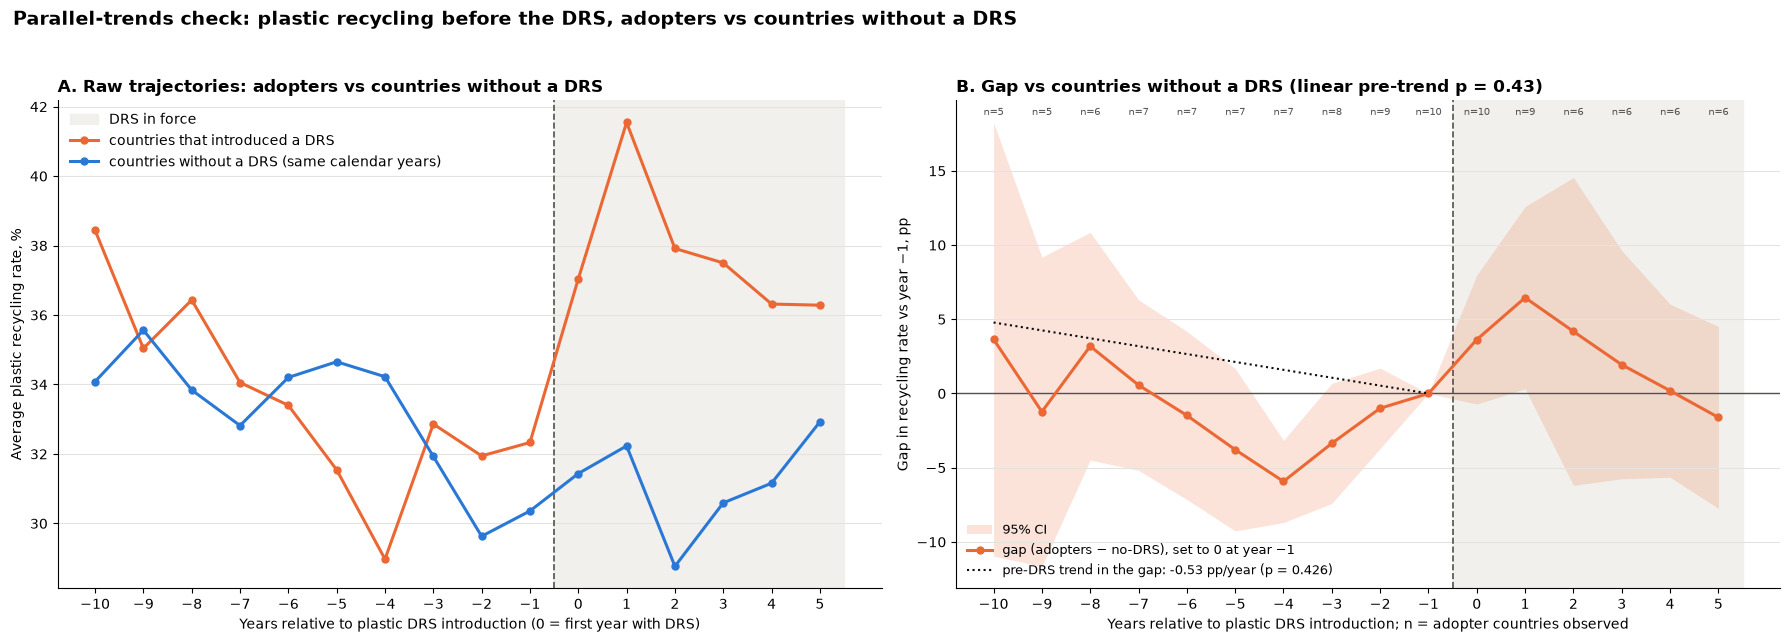

pre-DRS slope of the gap: -0.53 pp/year, SE 0.67, p = 0.426, 10 adopters


k,-10.0,-9.0,-8.0,-7.0,-6.0,-5.0,-4.0,-3.0,-2.0,-1.0,0.0,1.0,2.0,3.0,4.0,5.0
adopters,38.44,35.04,36.43,34.06,33.40,31.54,28.97,32.86,31.94,32.33,37.04,41.54,37.92,37.50,36.32,36.28
no_drs,34.08,35.56,33.84,32.82,34.20,34.65,34.22,31.93,29.63,30.36,31.44,32.23,28.77,30.59,31.16,32.92
gap,3.65,-1.23,3.19,0.57,-1.48,-3.78,-5.93,-3.36,-1.00,0.00,3.63,6.46,4.18,1.94,0.19,-1.61
se,7.45,5.31,3.91,2.93,2.89,2.79,1.41,2.06,1.38,0.00,2.22,3.13,5.29,3.92,2.98,3.13
n,5.00,5.00,6.00,7.00,7.00,7.00,7.00,8.00,9.00,10.00,10.00,9.00,6.00,6.00,6.00,6.00


In [7]:
# Parallel trends: did adopters and countries without a DRS move alike BEFORE the DRS started?
# Each adopter is compared with the mean of the no-DRS countries in the SAME calendar years.
never = panel.query("drs_group == '3_no_drs_in_window'").groupby("year")["plastic_recycling_rate"].mean()
pt = (panel.query("drs_group == '2_drs_introduced_in_window'")
           .dropna(subset=["plastic_recycling_rate"])[["geo", "year", "plastic_recycling_rate", "plastic_drs_start"]]
           .assign(k=lambda x: x["year"] - x["plastic_drs_start"],
                   control=lambda x: x["year"].map(never))
           .query("-10 <= k <= 5"))
pt["gap"] = pt["plastic_recycling_rate"] - pt["control"]
base = pt.query("k == -1").set_index("geo")["gap"]
pt = pt[pt["geo"].isin(base.index)]                      # need year -1 to normalise (drops HR)
pt["gap_norm"] = pt["gap"] - pt["geo"].map(base)

paths = pt.groupby("k").agg(adopters=("plastic_recycling_rate", "mean"), no_drs=("control", "mean"),
                            gap=("gap_norm", "mean"), se=("gap_norm", "sem"), n=("geo", "nunique"))

# Pre-trend slope: gap_norm = a_i + s * k over years before DRS, SE clustered by country
pre = pt.query("k < 0")
Xp = np.column_stack([pre["k"].to_numpy(float), pd.get_dummies(pre["geo"]).to_numpy(float)])
yp = pre["gap_norm"].to_numpy()
XtXi = np.linalg.pinv(Xp.T @ Xp)
bp = XtXi @ Xp.T @ yp
ep = yp - Xp @ bp
gi = pd.factorize(pre["geo"])[0]
Sp = np.vstack([np.bincount(gi, weights=Xp[:, j] * ep) for j in range(Xp.shape[1])]).T
Gp, (n_p, K_p) = Sp.shape[0], Xp.shape
Vp = XtXi @ (Sp.T @ Sp) @ XtXi * Gp / (Gp - 1) * (n_p - 1) / (n_p - K_p)
slope, slope_se = bp[0], np.sqrt(Vp[0, 0])
p_slope = chi2_sf((slope / slope_se) ** 2, 1)

fig, axes = plt.subplots(1, 2, figsize=(18, 6.5))
ax = axes[0]
ax.axvspan(-0.5, 5.5, color="#f1f0ec", zorder=0, label="DRS in force")
ax.axvline(-0.5, color="#52514e", lw=1.2, ls="--")
ax.plot(paths.index, paths["adopters"], color="#eb6834", lw=2.2, marker="o", markersize=5,
        label="countries that introduced a DRS")
ax.plot(paths.index, paths["no_drs"], color="#2a78d6", lw=2.2, marker="o", markersize=5,
        label="countries without a DRS (same calendar years)")
ax.set_xticks(paths.index)
ax.set_xlabel("Years relative to plastic DRS introduction (0 = first year with DRS)")
ax.set_ylabel("Average plastic recycling rate, %")
ax.set_title("A. Raw trajectories: adopters vs countries without a DRS", fontsize=12, fontweight="bold", loc="left")
ax.legend(frameon=False, loc="upper left")
ax.grid(axis="y", color="#e4e3df", lw=0.8)
ax.spines[["top", "right"]].set_visible(False)

ax = axes[1]
ax.axvspan(-0.5, 5.5, color="#f1f0ec", zorder=0)
ax.axhline(0, color="#52514e", lw=1)
ax.axvline(-0.5, color="#52514e", lw=1.2, ls="--")
ax.fill_between(paths.index, paths["gap"] - 1.96 * paths["se"], paths["gap"] + 1.96 * paths["se"],
                color="#eb6834", alpha=0.18, lw=0, label="95% CI")
ax.plot(paths.index, paths["gap"], color="#eb6834", lw=2.2, marker="o", markersize=5,
        label="gap (adopters − no-DRS), set to 0 at year −1")
kk = np.arange(-10, 0)
ax.plot(kk, slope * (kk + 1), color="#0b0b0b", lw=1.5, ls=":",
        label=f"pre-DRS trend in the gap: {slope:+.2f} pp/year (p = {p_slope:.3f})")
for k, cnt in paths["n"].items():
    ax.text(k, 0.97, f"n={cnt}", transform=ax.get_xaxis_transform(), ha="center", fontsize=7, color="#52514e")
ax.set_xticks(paths.index)
ax.set_xlabel("Years relative to plastic DRS introduction; n = adopter countries observed")
ax.set_ylabel("Gap in recycling rate vs year −1, pp")
ax.set_title(f"B. Gap vs countries without a DRS (linear pre-trend p = {p_slope:.2f})",
             fontsize=12, fontweight="bold", loc="left")
ax.legend(frameon=False, loc="lower left", fontsize=9)
ax.grid(axis="y", color="#e4e3df", lw=0.8)
ax.spines[["top", "right"]].set_visible(False)

fig.suptitle("Parallel-trends check: plastic recycling before the DRS, adopters vs countries without a DRS",
             fontsize=14, fontweight="bold", x=0.01, ha="left")
plt.tight_layout(rect=(0, 0, 1, 0.95))
plt.show()
print(f"pre-DRS slope of the gap: {slope:+.2f} pp/year, SE {slope_se:.2f}, p = {p_slope:.3f}, "
      f"{pre['geo'].nunique()} adopters")
display(paths.round(2).T)